# Retorno causal de un algoritmo de recomendación

**TPI Decision Intelligence Capstone — Estadística Aplicada y Modelos de Regresión (EAyMR 2026, UCA)**

| Integrante | Rol Scrum |
|---|---|
| Verónica López Marsico | Project Lead & Scrum Master |
| Lucía Báez | Backend & ML / Causal Engineer |
| Antonella Robiollio | Frontend & UI/UX + QA & Validation Engineer |

Notebook maestro (anexo del informe Quarto). Semilla global `SEED = 42`; nivel de significancia
fijado a priori α = 0,05. Uso de IA: `docs/ia_log.md`.

**Confidencialidad.** Las reglas de la competencia de Kaggle declaran confidenciales los datos.
Este notebook **nunca muestra registros individuales**: solo agregados, distribuciones y
resultados de contrastes. Los datos se regeneran con `python data/download_data.py`.

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repo por ruta relativa (funciona desde notebooks/, desde la raíz y en CI)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

from tpi import graficos as gr
from tpi.aleatorizacion import resumir_rho, rho_intra_busqueda
from tpi.auditoria import (
    agregar_competidores,
    aplicar_centinelas,
    cerca_tukey_log,
    contraste_mcar,
    diagnostico_escala_precio,
    imputar_con_indicador,
    precio_relativo,
    resumen_distribucion,
)
from tpi.config import SEED, set_global_seed
from tpi.contrato import contrato_activo
from tpi.inferencia import (
    anova_un_factor,
    contraste_pareado,
    describir_grupos,
    efecto_minimo_detectable,
    mann_whitney,
    posthoc,
    potencia,
    welch_dos_grupos,
)

warnings.filterwarnings("ignore", category=FutureWarning)
rng = set_global_seed(SEED)
gr.estilo()
pd.set_option("display.precision", 4)
CONTRATO = contrato_activo()
crudo = CONTRATO.cargar()
print(
    f"Contrato: {CONTRATO.nombre} | filas: {len(crudo):,} | búsquedas: {crudo['srch_id'].nunique():,}"
)

Contrato: expedia | filas: 739,323 | búsquedas: 30,000


---
# Fase 1 — Inferencia estadística clásica, diagnósticos y ANOVA

## 1.1 Diseño muestral y plan experimental

**Unidad de observación:** el par búsqueda × hotel $(s, i)$. **Unidad de muestreo:** la
búsqueda $s$. Los hoteles de una lista comparten usuario, fecha y destino, así que sus filas
no son independientes: muestrear filas sueltas rompería las listas y, en la Fase 3, filtraría
información entre Train y Test. Muestreamos 15.000 búsquedas completas por estrato de
`random_bool` (R), con semilla fija.

**Unidades independientes para los contrastes.** Todo contraste se hace sobre unidades
independientes: búsquedas (contrastes pareados dentro de la búsqueda) o reservas (a lo sumo
una por búsqueda). Nunca sobre filas, que darían errores estándar artificialmente chicos.

**Nivel de significancia y potencia.** Fijamos α = 0,05 antes de mirar los datos. Con miles de
unidades, cualquier diferencia minúscula es "significativa": por eso cada contraste reporta el
tamaño de efecto y el **efecto mínimo detectable** con potencia $1-\beta = 0{,}80$, que dice qué
puede y qué no puede ver la muestra.

In [2]:
busq = crudo.groupby("srch_id").agg(
    R=("random_bool", "first"),
    n_hoteles=("prop_id", "size"),
    reservas=("booking_bool", "sum"),
    clics=("click_bool", "sum"),
)
tabla_diseno = busq.groupby("R").agg(
    busquedas=("n_hoteles", "size"),
    filas=("n_hoteles", "sum"),
    hoteles_por_lista=("n_hoteles", "mean"),
    pct_con_reserva=("reservas", lambda s: 100 * (s >= 1).mean()),
    pct_con_clic=("clics", lambda s: 100 * (s >= 1).mean()),
)
tabla_diseno

,busquedas,filas,hoteles_por_lista,pct_con_reserva,pct_con_clic
R,,,,,
0,15000,376197,25.0798,94.16,100.0
1,15000,363126,24.2084,13.14,100.0


**Slots estructurales.** La cobertura media de las listas (hoteles observados / posición máxima)
es ≈ 0,87. Antes de atribuirlo a una remoción de filas, miramos en qué fracción de las búsquedas
aparece cada posición.

In [3]:
presencia = (
    crudo[crudo.position <= 30].groupby(["random_bool", "position"]).size().unstack(0)
    / crudo.groupby("random_bool")["srch_id"].nunique()
).rename(columns={0: "R = 0", 1: "R = 1"})
SLOTS_ESPECIALES = presencia.index[presencia.max(axis=1) < 0.2].tolist()
print("Posiciones presentes en < 20 % de las búsquedas:", SLOTS_ESPECIALES)
print(
    f"Acuerdo top5 (pantalla) vs. top4_dataset (sensibilidad): {100 * (crudo.top5 == crudo.top4_dataset).mean():.2f} % de las filas"
)
presencia.loc[[p for p in range(1, 13)]].T.round(3)

Posiciones presentes en < 20 % de las búsquedas: [5, 11, 17, 23]
Acuerdo top5 (pantalla) vs. top4_dataset (sensibilidad): 99.89 % de las filas


position,1,2,3,4,5,6,7,8,9,10,11,12
random_bool,,,,,,,,,,,,
R = 0,1.000,1.000,0.999,0.957,0.062,0.998,0.978,0.956,0.935,0.855,0.074,0.897
R = 1,0.995,0.995,0.995,0.990,0.016,0.993,0.969,0.944,0.923,0.897,0.017,0.882


Las posiciones 5, 11, 17 y 23 (un slot cada seis) aparecen en apenas 6-8 % de las búsquedas con
R = 0 y 1,4-1,7 % con R = 1, contra ≈ 99 % de sus vecinas. Son **slots fijos ocupados por listados
que no están en el dataset** (por ejemplo, anuncios u ofertas especiales), y explican casi todo el
13 % de posiciones faltantes. Consecuencias:

* El hueco es **estructural**, no una remoción de hoteles según sus atributos. Por lo tanto **no
  explica** la asociación residual posición–atributo observada con R = 1 (`docs/ia_log.md`,
  error 10), que sigue abierta.
* $T = 1\{\text{position} \le 5\}$ se mantiene definido sobre la posición **en pantalla** (así la
  define Kaggle), pero en la práctica el top-5 contiene casi siempre 4 hoteles del dataset
  (posiciones 1-4): el quinto slot lo ocupa otro listado.
* Las filas que sí ocupan esos slots son pocas y atípicas (tasa de clic muy baja, ver 1.5). Se
  conservan, pero se señalan con un indicador (`slot_especial`).
* **T de sensibilidad** (decisión de Verónica, 12/11): `top4_dataset` = los 4 primeros hoteles
  del dataset en el ranking de la búsqueda. Coincide con `top5` en el 99,89 % de las filas (output
  de `tpi.contrato`); la Fase 4 reporta ambas.

## 1.2 Auditoría forense de datos

Auditamos la génesis de cada anomalía y cuantificamos la distorsión antes y después del
tratamiento. Cuatro familias: **centinelas**, **desplazamiento de escala del precio**,
**valores extremos** y **faltantes** (sección 1.3).

### Centinelas

Tres variables usan el 0 como código de "no hay dato": `prop_review_score` (hotel sin reseñas),
`prop_starrating` (sin categoría) y `prop_log_historical_price` (sin ventas en el período
previo). Tratarlas como valores reales sesga medias y desvíos. Las pasamos a NaN y conservamos un
indicador binario, porque la ausencia de información es en sí misma una señal para el ranker y
para el usuario.

In [4]:
df, tabla_centinelas = aplicar_centinelas(crudo)
df["slot_especial"] = df["position"].isin(SLOTS_ESPECIALES).astype("int8")  # ver 1.1
tabla_centinelas

,centinela,pct_filas,media_antes,media_despues,sesgo_media_pct,desvio_antes,desvio_despues
variable,,,,,,,
prop_review_score,0.0,5.1705,3.7577,3.9629,-5.1792,1.0822,0.6495
prop_starrating,0.0,3.3731,3.1859,3.2972,-3.3731,1.0504,0.8804
prop_log_historical_price,0.0,14.8256,4.3048,5.0541,-14.8256,1.8601,0.5248


### Desplazamiento de escala del precio

`price_usd` debería ser el precio por noche y por habitación. Lo verificamos con la única
fuente externa disponible, el gasto real de las reservas:

$$r^{\text{noche}} = \frac{\text{gross\_bookings\_usd}}{\text{price} \cdot \text{noches} \cdot \text{habitaciones}}, \qquad
  r^{\text{estadía}} = \frac{\text{gross\_bookings\_usd}}{\text{price} \cdot \text{habitaciones}}.$$

Si el precio es por noche, $r^{\text{noche}} \approx 1{,}1$ (impuestos y tasas). Si es por
estadía, $r^{\text{estadía}} \approx 1{,}1$. Con una noche ambas coinciden, así que las usamos
para calibrar la banda de tolerancia, y clasificamos solo las estadías de dos o más noches.

In [5]:
reservas_1n = df[
    (df.booking_bool == 1) & (df.gross_bookings_usd > 0) & (df.srch_length_of_stay == 1)
]
r1 = reservas_1n.gross_bookings_usd / (reservas_1n.price_usd * reservas_1n.srch_room_count)
print(
    "Calibración (1 noche), cuantiles 5/25/50/75/95 % de la razón:",
    r1.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).tolist(),
)
escala = diagnostico_escala_precio(df)
tabla_escala = escala["escala"].value_counts().to_frame("reservas")
tabla_escala["pct"] = 100 * tabla_escala["reservas"] / tabla_escala["reservas"].sum()
por_sitio = escala.groupby("site_id").agg(
    n=("escala", "size"), pct_por_estadia=("escala", lambda s: 100 * (s == "por_estadia").mean())
)
print(
    "Sitios con ≥ 100 reservas: % por estadía entre",
    por_sitio.query("n >= 100").pct_por_estadia.min().round(2),
    "y",
    por_sitio.query("n >= 100").pct_por_estadia.max().round(2),
)
tabla_escala

Calibración (1 noche), cuantiles 5/25/50/75/95 % de la razón: [0.95, 1.102, 1.134, 1.19, 1.509]
Sitios con ≥ 100 reservas: % por estadía entre 1.87 y 7.48


,reservas,pct
escala,,
por_noche,7225,87.4591
incompatible,771,9.3330
por_estadia,265,3.2078


### Valores extremos de precio

Dos reglas complementarias:

* **Absoluta:** cercas extremas de Tukey sobre $\log(\text{precio})$, $[Q_1 - 3\,\mathrm{IQR},\; Q_3 + 3\,\mathrm{IQR}]$.
  Detecta búsquedas enteras con precios imposibles, que la regla relativa no ve porque la
  mediana de la búsqueda también es absurda.
* **Relativa:** precio mayor que 10 veces (o menor que 1/10 de) la mediana de su búsqueda.

**Variable de trabajo:** precio relativo a la mediana de la búsqueda (winsorizado en los
percentiles 1 y 99) y su logaritmo. Es invariante a cualquier escala común de la lista (por
noche vs. por estadía, moneda) y mide lo que el usuario ve: si el hotel es caro *para esa
búsqueda*.

In [6]:
df = precio_relativo(df)
lo_abs, hi_abs = cerca_tukey_log(df["price_usd"])
print(
    f"Cercas absolutas: [{lo_abs:.2f}; {hi_abs:.2f}] USD | outliers: {df.precio_outlier.sum():,} filas ({100 * df.precio_outlier.mean():.3f} %)"
)
distorsion = pd.DataFrame(
    {
        "price_usd (crudo)": resumen_distribucion(df["price_usd"]),
        "price_usd sin outliers": resumen_distribucion(df.loc[df.precio_outlier == 0, "price_usd"]),
        "log precio relativo": resumen_distribucion(df["log_precio_rel"]),
    }
).T
distorsion

Cercas absolutas: [8.41; 1951.14] USD | outliers: 1,445 filas (0.195 %)


,n,media,desvio,asimetria,p50,p99,max
price_usd (crudo),739323.0,237.6314,10152.1004,237.0404,125.0,639.0000,4.1217e+06
price_usd sin outliers,737878.0,157.1369,119.6814,3.6310,125.0,611.1723,1.9500e+03
log precio relativo,739323.0,0.0106,0.3932,0.2854,0.0,1.1888,1.1888e+00


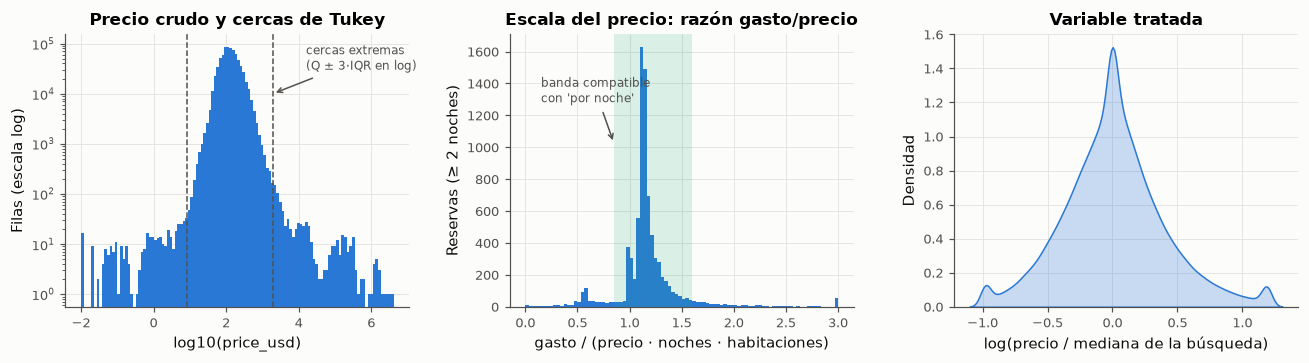

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
lp = np.log10(df["price_usd"].clip(lower=0.01))
ax[0].hist(lp, bins=120, color=gr.AZUL)
for c in (lo_abs, hi_abs):
    ax[0].axvline(np.log10(c), color=gr.TEXTO_2, ls="--", lw=1)
ax[0].set(
    yscale="log",
    xlabel="log10(price_usd)",
    ylabel="Filas (escala log)",
    title="Precio crudo y cercas de Tukey",
)
ax[0].annotate(
    "cercas extremas\n(Q ± 3·IQR en log)",
    xy=(np.log10(hi_abs), 1e4),
    xytext=(4.2, 3e4),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
razones = escala["razon_noche"].clip(0, 3)
ax[1].hist(razones, bins=90, color=gr.AZUL)
ax[1].axvspan(0.85, 1.6, color=gr.AQUA, alpha=0.15, lw=0)
ax[1].set(
    xlabel="gasto / (precio · noches · habitaciones)",
    ylabel="Reservas (≥ 2 noches)",
    title="Escala del precio: razón gasto/precio",
)
ax[1].annotate(
    "banda compatible\ncon 'por noche'",
    xy=(0.85, ax[1].get_ylim()[1] * 0.6),
    xytext=(0.15, ax[1].get_ylim()[1] * 0.75),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
sns.kdeplot(df["log_precio_rel"], ax=ax[2], color=gr.AZUL, fill=True, alpha=0.25, bw_adjust=1.5)
ax[2].set(
    xlabel="log(precio / mediana de la búsqueda)", ylabel="Densidad", title="Variable tratada"
)
fig.tight_layout()
gr.guardar(fig, "f1_precio_auditoria")
plt.show()

## 1.3 Mecanismo de pérdida de datos (MCAR, MAR, MNAR)

Sea $R_j = 1\{X_j \text{ falta}\}$. **MCAR**: $P(R_j \mid X_{\text{obs}}, X_{\text{mis}}) = P(R_j)$.
**MAR**: $P(R_j \mid X_{\text{obs}}, X_{\text{mis}}) = P(R_j \mid X_{\text{obs}})$. **MNAR**: depende del propio valor
faltante. MCAR implica que $R_j$ es independiente de **toda** variable observada, y eso es
contrastable: comparamos $R_j$ contra variables observadas (χ² de independencia para binarias,
Mann-Whitney para continuas, Bonferroni por familia). MAR vs. MNAR **no** es contrastable con
los datos: se argumenta por el mecanismo de generación.

Con cientos de miles de filas, casi cualquier dependencia da p ≈ 0. Por eso la lectura se apoya
en el tamaño de efecto: $|\text{SMD}| \ge 0{,}1$ o $V \ge 0{,}1$ es dependencia apreciable.

In [8]:
faltantes = (
    df[[c for c in df.columns if df[c].isna().any() and not c.startswith("comp")]]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .to_frame("pct_faltante")
)
faltantes

,pct_faltante
gross_bookings_usd,97.8230
visitor_hist_starrating,95.5182
visitor_hist_adr_usd,95.5143
srch_query_affinity_score,94.2999
orig_destination_distance,32.8042
prop_location_score2,22.0433
prop_log_historical_price,14.8256
prop_review_score,5.3376
prop_starrating,3.3731


In [9]:
CONTRA = [
    "booking_bool",
    "click_bool",
    "random_bool",
    "prop_starrating",
    "log_precio_rel",
    "prop_location_score1",
    "srch_booking_window",
]
mcar = pd.concat(
    [
        contraste_mcar(df, c, [v for v in CONTRA if v != c])
        for c in [
            "prop_location_score2",
            "orig_destination_distance",
            "prop_review_score",
            "visitor_hist_starrating",
            "srch_query_affinity_score",
        ]
    ]
)
resumen_mcar = mcar.pivot(index="variable_faltante", columns="contra", values="efecto").round(3)
resumen_mcar["max_|efecto|"] = resumen_mcar.abs().max(axis=1)
resumen_mcar

contra,booking_bool,click_bool,log_precio_rel,prop_location_score1,prop_starrating,random_bool,srch_booking_window,max_|efecto|
variable_faltante,,,,,,,,
orig_destination_distance,0.001,0.007,0.019,0.229,0.304,0.024,0.196,0.304
prop_location_score2,0.043,0.050,-0.030,-0.506,-0.257,0.019,-0.104,0.506
prop_review_score,0.020,0.016,-0.000,-0.238,-0.049,0.050,0.146,0.238
srch_query_affinity_score,0.014,0.000,0.014,0.132,0.180,0.082,0.112,0.180
visitor_hist_starrating,0.014,0.000,0.003,-0.012,-0.080,0.072,0.091,0.091


**Lectura (efectos de la tabla; ver `contraste_mcar` para p-valores con Bonferroni):**

| Variable | % faltante | Dependencia observada | Mecanismo | Tratamiento |
|---|---|---|---|---|
| `prop_location_score2` | 22,0 | SMD = −0,506 con `location_score1`; −0,257 con estrellas; V = 0,043 con reserva | **MAR**: el faltante se explica por variables observadas del hotel (hoteles peor ubicados y de menos estrellas) | Mediana por país + indicador `_faltante` |
| `orig_destination_distance` | 32,8 | SMD = 0,304 con estrellas; 0,229 con `location_score1`; 0,196 con anticipación | **MAR**: falla de geolocalización asociada a perfiles observables | Mediana por par (país del usuario, país del hotel) + indicador |
| `prop_review_score` (incl. centinela 0) | 5,3 | SMD = −0,238 con `location_score1`; 0,146 con anticipación | **MNAR estructural**: el hotel no tiene reseñas; el valor no existe | Mediana por estrellas + indicador `sin_resenas`, que conserva la información |
| `visitor_hist_starrating` / `_adr_usd` | 95,5 | Todas las dependencias < 0,1 (máx. 0,091) | **MNAR estructural**: el usuario no tiene compras previas; no hay valor que imputar | **No se imputa**: se usa `usuario_recurrente` |
| `srch_query_affinity_score` | 94,3 | SMD = 0,180 con estrellas | **MNAR estructural**: el hotel no apareció en búsquedas previas | **No se imputa**: indicador `con_afinidad` |
| `gross_bookings_usd` | 97,8 | Existe solo si `booking_bool = 1` | Estructural por diseño | Solo se analiza entre reservas |

**MCAR se rechaza para las cinco variables contrastadas** (en todas hay al menos una dependencia
con p ajustado < 0,05), aunque para `visitor_hist_starrating` ninguna dependencia es apreciable.
La imputación por mediana dentro de grupos es coherente con MAR condicional al grupo, y el
indicador evita que el modelo trate el valor imputado como observado. Un faltante MNAR
estructural **no se imputa**: imputar un historial que no existe inventaría información.

In [10]:
df["usuario_recurrente"] = df["visitor_hist_starrating"].notna().astype("int8")
df["con_afinidad"] = df["srch_query_affinity_score"].notna().astype("int8")
df = imputar_con_indicador(df, "prop_location_score2", por=["prop_country_id"])
df = imputar_con_indicador(df, "prop_review_score", por=["prop_starrating"])
df = imputar_con_indicador(df, "prop_starrating")
df = imputar_con_indicador(df, "prop_log_historical_price", por=["prop_country_id"])
df = imputar_con_indicador(
    df, "orig_destination_distance", por=["visitor_location_country_id", "prop_country_id"]
)
print(
    "NaN restantes en variables de ajuste:",
    int(
        df[
            [
                "prop_location_score2",
                "prop_review_score",
                "prop_starrating",
                "prop_log_historical_price",
                "orig_destination_distance",
            ]
        ]
        .isna()
        .sum()
        .sum()
    ),
)

NaN restantes en variables de ajuste: 0


## 1.4 Variables de competidores ($Z_c$): ¿confusor o predictor?

**Definiciones (fuente primaria: pestaña Data de la competencia, transcriptas y verificadas por
Verónica el 12/11):**

* `compN_rate`: "+1 if Expedia has a lower price than competitor N for the hotel; 0 if the same;
  -1 if Expedia's price is higher than competitor N; NULL signifies there is no competitive data".
  **+1 = Expedia más barata.**
* `compN_inv`: "+1 if competitor N does not have availability in the hotel; 0 if both Expedia and
  competitor N have availability; NULL signifies there is no competitive data". En los datos
  aparece también **−1**, un valor no documentado (ver la tabla siguiente); no lo interpretamos.
* `compN_rate_percent_diff`: diferencia porcentual **absoluta** (sin signo; la dirección sale de
  `compN_rate`), con el precio de Expedia como denominador.

**Criterio de clasificación (fijado por Verónica antes del análisis):** $Z_c$ es **confusor** si el
ranking la usa ($Z_c \to T$) **y** además afecta la reserva ($Z_c \to Y$). Si solo afecta $Y$, es
**predictor**: puede incluirse por precisión, pero no integra el conjunto de ajuste mínimo de
Backdoor. Las dos flechas se contrastan por separado:

* **$Z_c \to T$:** el orden aleatorio (R = 1) corta los arcos que entran a T. Si el ranker usa
  $Z_c$, la asociación entre $Z_c$ y T con R = 0 debe **debilitarse** con R = 1. Se mide de tres
  formas: (a) $\rho$ de Spearman intra-búsqueda posición–$Z_c$; (b) diferencia pareada por
  búsqueda $D_s = \bar Z_{c,\text{top-5}} - \bar Z_{c,\text{resto}}$, en cada estrato; (c) logit de
  T sobre $Z_c$ y $Z_h$ con interacción $Z_c \times R$ (errores por clúster de búsqueda). (c) es
  el contraste formal: $H_0$: el efecto de $Z_c$ sobre T, condicional a $Z_h$, es igual con y sin
  el ranker.
* **$Z_c \to Y$:** con R = 1, logit de la reserva (y del clic, su mediador obligado) sobre $Z_c$,
  controlando por $\log(\text{posición})$ y por calidad y precio, con errores por clúster.

Resumen de los 8 competidores (entre 56 % y 98 % de faltantes): `comp_n_info` = competidores con
dato de precio; `comp_saldo` = (n con rate = +1 − n con rate = −1) / n con dato, en $[-1, 1]$:
**positivo = Expedia más barata que la mayoría de los competidores con dato**; `comp_diff_max` =
máxima diferencia porcentual absoluta válida (≤ 100 %).

In [11]:
inv = pd.concat([df[f"comp{i}_inv"].value_counts() for i in range(1, 9)], axis=1).sum(axis=1)
print(
    "compN_inv (8 competidores, valores no nulos):",
    inv.astype(int).to_dict(),
    f"| −1 no documentado: {100 * inv.get(-1.0, 0) / inv.sum():.2f} %",
)
diff_min = min(df[f"comp{i}_rate_percent_diff"].min() for i in range(1, 9))
print(f"Mínimo de compN_rate_percent_diff en los 8 competidores: {diff_min}")

compN_inv (8 competidores, valores no nulos): {0.0: 1235718, 1.0: 76325, -1.0: 16865} | −1 no documentado: 1.27 %
Mínimo de compN_rate_percent_diff en los 8 competidores: 2.0


In [12]:
df = agregar_competidores(df)
df["log_pos"] = np.log(df["position"])
ZH = "prop_starrating + prop_review_score + prop_location_score2 + log_precio_rel + promotion_flag"
filas_zc = []
for v in ["comp_n_info", "comp_saldo", "comp_diff_max"]:
    fila = {"variable": v}
    # (a) rho intra-búsqueda posición–Zc, por estrato
    for r in (0, 1):
        fila[f"rho_R{r}"] = resumir_rho(rho_intra_busqueda(df[df.random_bool == r], v), v).rho_medio
    # (b) diferencia pareada top-5 − resto, por estrato
    for r in (0, 1):
        d = df[df.random_bool == r].dropna(subset=[v])
        g = d.groupby(["srch_id", "top5"])[v].mean().unstack().dropna()
        c = contraste_pareado(g[1] - g[0])
        fila[f"D_R{r}"], fila[f"p_D_R{r}"] = c.diferencia, c.p_valor
    # (c) interacción Zc × R en el logit de T, condicional a Zh
    d = df.dropna(subset=[v])
    f = smf.logit(f"top5 ~ {v}*random_bool + ({ZH})*random_bool", d).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": d["srch_id"]}
    )
    fila["OR_T_R0"] = float(np.exp(f.params[v]))
    fila["razon_OR_T_R1/R0"] = float(np.exp(f.params[f"{v}:random_bool"]))
    fila["p_interaccion"] = float(f.pvalues[f"{v}:random_bool"])
    # Zc -> Y (y -> M) con R = 1
    d1 = df[df.random_bool == 1].dropna(subset=[v])
    for y in ["click_bool", "booking_bool"]:
        f = smf.logit(
            f"{y} ~ {v} + log_pos + prop_starrating + prop_review_score + log_precio_rel", d1
        ).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d1["srch_id"]})
        fila[f"OR_{y}"] = float(np.exp(f.params[v]))
        fila[f"p_{y}"] = float(f.pvalues[v])
    filas_zc.append(fila)
tabla_zc = pd.DataFrame(filas_zc).set_index("variable")
tabla_zc.T

variable,comp_n_info,comp_saldo,comp_diff_max
rho_R0,-9.8626e-02,-3.7199e-02,-1.5721e-02
rho_R1,-3.3221e-02,7.3544e-03,-1.1588e-03
D_R0,1.0004e-01,4.8751e-02,1.2296e+00
p_D_R0,1.8832e-97,1.0561e-59,3.4244e-19
D_R1,2.6710e-02,-5.6890e-03,2.8623e-01
p_D_R1,1.9384e-09,7.2598e-02,6.2761e-02
OR_T_R0,9.4789e-01,1.1728e+00,1.0025e+00
razon_OR_T_R1/R0,1.0193e+00,8.4230e-01,9.9859e-01
p_interaccion,2.8375e-05,2.6854e-18,5.3778e-02
OR_click_bool,9.9487e-01,1.1467e+00,1.0002e+00


**Clasificación** (criterio de Verónica; aplicación de Claude Code; **pendiente de revisión por
Verónica**; incluye el contraste explícito de $Z_c \to T$ que ella pidió el 12/11):

| Variable | $Z_c \to T$ (ranker) | $Z_c \to Y$ (R = 1) | Clase |
|---|---|---|---|
| `comp_saldo` | Con R = 0 el top-5 tiene más saldo (D = +0,049, p = 1,1·10⁻⁵⁹); con R = 1 desaparece (D = −0,006, p = 0,073). Interacción: razón de OR 0,842, p = 2,7·10⁻¹⁸ | Reserva OR = 1,137 (p = 0,041); clic OR = 1,147 (p = 2,1·10⁻⁸) | **Confusor** |
| `comp_n_info` | D = +0,100 con R = 0 vs. +0,027 con R = 1 (cae 73 %). Condicional a $Z_h$, OR(T) = 0,948 con R = 0; interacción: razón 1,019, p = 2,8·10⁻⁵ | Reserva OR = 1,118 (p = 2,9·10⁻¹⁷); clic sin efecto (p = 0,20) | **Confusor (débil en T)** |
| `comp_diff_max` | Interacción p = 0,054: no se rechaza H0 | Reserva p = 0,53; clic p = 0,79 | **Ni confusor ni predictor**: se excluye |

**Lectura con el signo correcto.** `comp_saldo` > 0 significa que Expedia es más barata que la
mayoría de los competidores con dato. Bajo el orden del algoritmo, los hoteles con precio
competitivo suben al top-5 (OR(T) = 1,173 por unidad de saldo, condicional a calidad y precio
relativo). Con la posición aleatoria, ese mismo precio competitivo aumenta el clic (+14,7 % en las
chances) y la reserva (+13,7 %). Como el ranker usa una variable que también causa la reserva por
su cuenta, omitirla sesgaría el efecto del top-5 hacia arriba.

**`comp_n_info`** pasa el criterio, pero su arco a T es chico (≈ 2 % en las chances, condicional a
$Z_h$), y la asociación residual con R = 1 (D = +0,027, p = 1,9·10⁻⁹) es del mismo tipo que la
aleatorización imperfecta de `prop_starrating` (limitación declarada, Entrada 4). Incluirla en el
ajuste es seguro: es pre-tratamiento, no es mediador ni colisionador.

**DAG actualizado** (`src/tpi/dag.py`): se agregan $Z_c \to T$ y $Z_c \to M$, y $Z_c$ pasa al conjunto de
confusores. `tests/test_dag.py::test_sin_zc_el_ajuste_no_alcanza_aunque_se_observara_u` demuestra que
omitir $Z_c$ deja abierto $T \leftarrow Z_c \to Y$.

## 1.5 Análisis exploratorio univariado y bivariado

La figura central del problema: la tasa de clic por posición con el orden del algoritmo
(R = 0) y con el orden aleatorio (R = 1). Bajo R = 1 la caída con la posición es **sesgo de
posición** puro (el arco $T \to M$). Bajo R = 0 se le suma la calidad de los hoteles que el
algoritmo pone arriba (confusión). La distancia entre ambas curvas es la primera evidencia
visual del sesgo que la Fase 4 tiene que corregir.

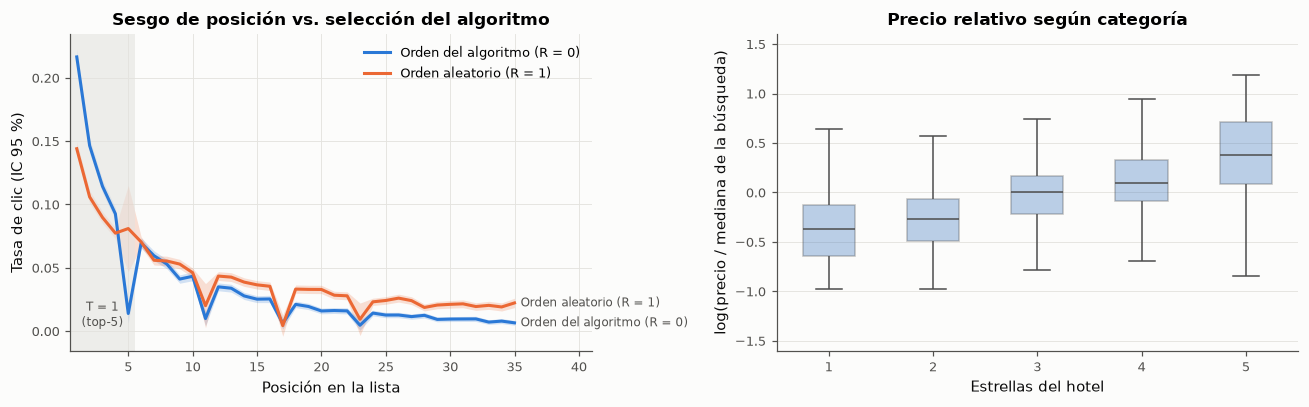

In [13]:
ctr = (
    df[df.position <= 35]
    .groupby(["random_bool", "position"])["click_bool"]
    .agg(["mean", "count"])
    .reset_index()
)
ctr["ee"] = np.sqrt(ctr["mean"] * (1 - ctr["mean"]) / ctr["count"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for r, color, nombre in [
    (0, gr.AZUL, "Orden del algoritmo (R = 0)"),
    (1, gr.NARANJA, "Orden aleatorio (R = 1)"),
]:
    d = ctr[ctr.random_bool == r]
    ax[0].plot(d.position, d["mean"], color=color, label=nombre)
    ax[0].fill_between(
        d.position, d["mean"] - 1.96 * d.ee, d["mean"] + 1.96 * d.ee, color=color, alpha=0.2, lw=0
    )
    ax[0].annotate(
        nombre,
        xy=(d.position.iloc[-1], d["mean"].iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        fontsize=8,
        color=gr.TEXTO_2,
        va="center",
    )
ax[0].axvspan(0.5, 5.5, color=gr.GRILLA, alpha=0.6, lw=0)
ax[0].text(3, 0.004, "T = 1\n(top-5)", ha="center", fontsize=8, color=gr.TEXTO_2)
ax[0].set(
    xlabel="Posición en la lista",
    ylabel="Tasa de clic (IC 95 %)",
    title="Sesgo de posición vs. selección del algoritmo",
    xlim=(0.5, 41),
)
ax[0].legend(loc="upper right")
grupos_est = df.dropna(subset=["prop_starrating"]).assign(
    estrellas=lambda d: d.prop_starrating.astype(int).astype(str)
)
sns.boxplot(
    data=grupos_est,
    x="estrellas",
    y="log_precio_rel",
    order=["1", "2", "3", "4", "5"],
    color=gr.AZUL,
    ax=ax[1],
    fliersize=0,
    width=0.5,
    boxprops={"alpha": 0.35},
)
ax[1].set(
    xlabel="Estrellas del hotel",
    ylabel="log(precio / mediana de la búsqueda)",
    title="Precio relativo según categoría",
    ylim=(-1.6, 1.6),
)
fig.tight_layout()
gr.guardar(fig, "f1_ctr_posicion")
plt.show()

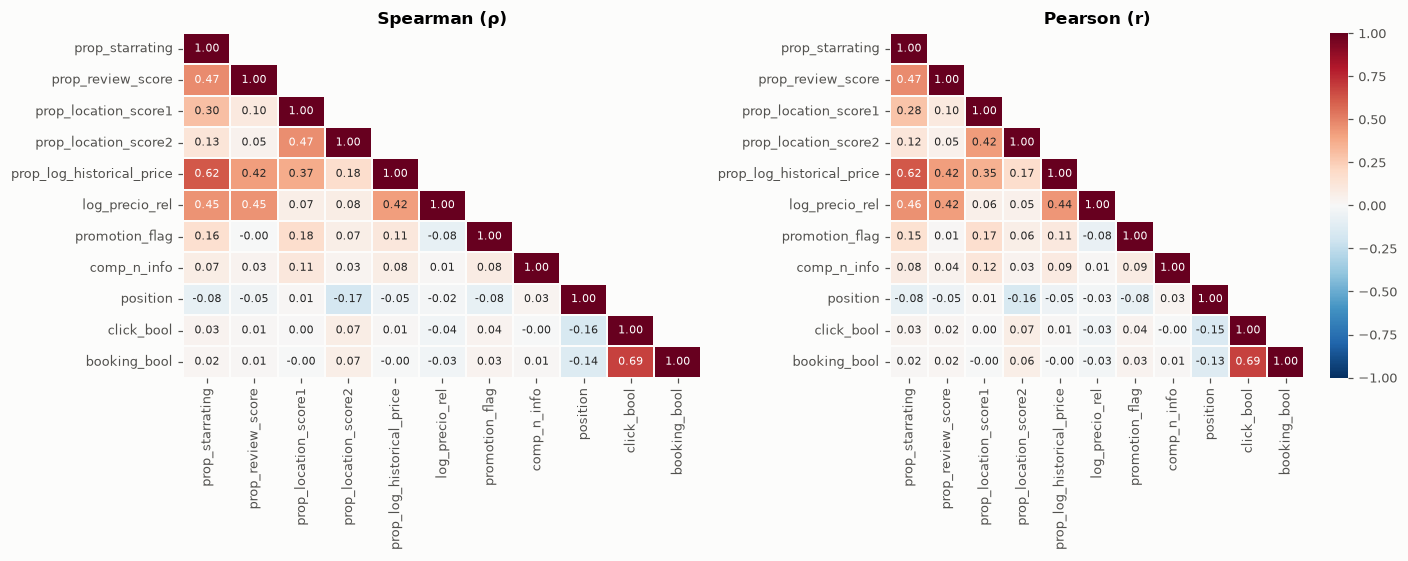

Mayor |ρ_Spearman − r_Pearson|: {('prop_location_score2', 'prop_location_score1'): 0.043, ('prop_location_score1', 'prop_location_score2'): 0.043, ('prop_review_score', 'log_precio_rel'): 0.03}


,ρ con position,ρ con booking_bool
prop_starrating,-0.082,0.017
prop_review_score,-0.045,0.013
prop_location_score1,0.013,-0.004
prop_location_score2,-0.172,0.065
prop_log_historical_price,-0.054,-0.000
log_precio_rel,-0.023,-0.032
promotion_flag,-0.082,0.032
comp_n_info,0.029,0.013
click_bool,-0.160,0.686


In [14]:
NUM = [
    "prop_starrating",
    "prop_review_score",
    "prop_location_score1",
    "prop_location_score2",
    "prop_log_historical_price",
    "log_precio_rel",
    "promotion_flag",
    "comp_n_info",
    "position",
    "click_bool",
    "booking_bool",
]
corr_s = df[NUM].corr(method="spearman")
corr_p = df[NUM].corr(method="pearson")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
mascara = np.triu(np.ones_like(corr_s, dtype=bool), k=1)
for a, c, t in [(ax[0], corr_s, "Spearman (ρ)"), (ax[1], corr_p, "Pearson (r)")]:
    sns.heatmap(
        c,
        mask=mascara,
        cmap=gr.DIVERGENTE,
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        linewidths=1,
        linecolor=gr.SUPERFICIE,
        cbar=a is ax[1],
        ax=a,
    )
    a.set_title(t)
    a.grid(False)
fig.tight_layout()
gr.guardar(fig, "f1_correlaciones")
plt.show()
print(
    "Mayor |ρ_Spearman − r_Pearson|:",
    (corr_s - corr_p).abs().stack().sort_values(ascending=False).head(3).round(3).to_dict(),
)
pd.DataFrame(
    {"ρ con position": corr_s["position"], "ρ con booking_bool": corr_s["booking_bool"]}
).drop(["position", "booking_bool"]).round(3)

**Lectura de la exploración:**

* **Sesgo de posición.** Con orden aleatorio, la tasa de clic cae con la posición (el arco
  $T \to M$ existe). Con el orden del algoritmo, la curva arranca más alta en el top-5 y cae más
  abajo al final de la lista: el algoritmo concentra arriba a los hoteles que se clickean igual.
  La brecha entre curvas es la confusión que la Fase 4 debe eliminar. Los "pozos" en 5, 11, 17 y
  23 son los slots estructurales (1.1).
* **Calidad y precio.** El precio relativo sube con las estrellas: calidad y precio están
  entrelazados, lo que anticipa multicolinealidad en la Fase 2.
* **Correlaciones.** Spearman y Pearson difieren a lo sumo en 0,043 (entre los dos scores de
  ubicación), así que las relaciones son aproximadamente monótonas y lineales en estas escalas. La
  variable más asociada a la posición es `prop_location_score2` (ρ = −0,172: mejor ubicación, más
  arriba), seguida por el clic (−0,160), las estrellas (−0,082) y la promoción (−0,082). Con la
  reserva, la asociación más fuerte es el clic (ρ = 0,686, el mediador), seguida por la posición
  (ρ = −0,14 en la matriz). Las demás son débiles (`location_score2`: 0,065).
* **Colinealidad anticipada.** `prop_log_historical_price` correlaciona 0,62 con las estrellas, y
  el precio relativo, 0,45 con estrellas y con reseñas: bloque calidad–precio a auditar con VIF en
  la Fase 2.
* Son correlaciones a nivel fila, sin separar R = 0 de R = 1: descriptivas, no causales.

## 1.6 Contraste 1 — Sesgo de posición en el clic (pareado, R = 1)

**Pregunta de negocio:** si el orden es aleatorio, ¿los hoteles del top-5 reciben más clics que
el resto *de la misma lista*? Es el primer eslabón del DAG ($T \to M$): si no existiera, el slot
no tendría valor causal.

Para cada búsqueda $s$ con R = 1: $D_s = \overline{\text{CTR}}_{s,\text{top-5}} - \overline{\text{CTR}}_{s,\text{resto}}$.

$$H_0: \mathbb{E}[D_s] = 0 \qquad H_1: \mathbb{E}[D_s] \neq 0$$

**Estadístico:** t de Student para una muestra sobre las diferencias pareadas,
$t = \bar D / (s_D/\sqrt{n})$ con $n-1$ gl. Es pareado porque las dos tasas comparten búsqueda
(usuario, destino, fecha), lo que elimina todo confusor a nivel búsqueda. La validez descansa en
el TCL ($n$ en miles); como resguardo no paramétrico, Wilcoxon de rangos con signo. Tamaño de
efecto: $d_z = \bar D / s_D$.

**Selección:** el dataset solo trae búsquedas con al menos un clic (BITÁCORA, Entrada 4). Eso
infla ambas tasas, pero dentro de la búsqueda el cociente se conserva aproximadamente, así que
también reportamos el cociente de tasas medias.

In [15]:
r1_df = df[df.random_bool == 1]
por_busq = (
    r1_df.assign(T=(r1_df.position <= 5)).groupby(["srch_id", "T"])["click_bool"].mean().unstack()
)
por_busq = por_busq.dropna()
D = por_busq[True] - por_busq[False]
c1 = contraste_pareado(D, nombre="Contraste 1 (CTR top-5 − resto, R = 1)")
print(c1.texto())
print(f"Wilcoxon: W = {c1.extra['wilcoxon_W']:.4g}, p = {c1.extra['wilcoxon_p']:.3g}")
print(
    f"CTR medio top-5 = {por_busq[True].mean():.4f} | resto = {por_busq[False].mean():.4f} | cociente = {por_busq[True].mean() / por_busq[False].mean():.3f}"
)
print(
    f"Efecto mínimo detectable (d_z, 1−β = 0,80): {efecto_minimo_detectable(len(D)):.4f} | potencia para el d_z observado: {potencia(c1.efecto, len(D)):.4f}"
)
print(f"Asimetría de D: {stats.skew(D):.3f} | curtosis en exceso: {stats.kurtosis(D):.3f}")

Contraste 1 (CTR top-5 − resto, R = 1): t(14982) = 37.47, p = 7.74e-294, IC 95 % [0.05313; 0.05899], d_z = 0.306 (α = 0.05) → se rechaza H0
Wilcoxon: W = 4.326e+07, p = 7.7e-131
CTR medio top-5 = 0.1043 | resto = 0.0483 | cociente = 2.161
Efecto mínimo detectable (d_z, 1−β = 0,80): 0.0229 | potencia para el d_z observado: 1.0000
Asimetría de D: -0.540 | curtosis en exceso: 3.608


**Decisión.** Se rechaza $H_0$: t(14982) = 37,47, p = 7,74·10⁻²⁹⁴. Con orden aleatorio, los hoteles
del top-5 tienen una tasa de clic 5,6 puntos porcentuales mayor que el resto de su propia lista
(IC 95 % [5,31; 5,90] p.p.), y $d_z = 0{,}306$ (efecto pequeño a mediano en la escala de Cohen). El
Wilcoxon de resguardo coincide (p = 7,7·10⁻¹³¹), así que la conclusión no depende de la
normalidad: $D_s$ tiene asimetría −0,540 y curtosis en exceso 3,608, que el TCL absorbe con
n = 14.983.

**Escala relativa.** La tasa de clic media del top-5 es 0,1043 contra 0,0483 del resto: un
cociente de **2,16**. Por la selección del dataset (solo búsquedas con clic) las tasas absolutas
están infladas, pero el cociente dentro de la búsqueda es la escala que se conserva (Entrada 4).

**Potencia.** Con n = 14.983 el efecto mínimo detectable es $d_z$ = 0,023: la muestra detectaría
efectos 13 veces menores que el observado.

**Negocio.** Sin mirar la calidad del hotel, estar en el top-5 duplica la probabilidad de clic.
Ese es el valor *bruto* del slot sobre la atención; falta saber cuánto se traduce en reservas
(Fase 4).

## 1.7 Contraste 2 — Gasto por reserva: usuarios recurrentes vs. nuevos

**Pregunta de negocio:** ¿los usuarios con historial de compras en Expedia (recurrentes) gastan
más por reserva que los nuevos? Es la "autoselección de usuarios recurrentes" del enunciado: si
gastan distinto, el historial ($Z_u$) es candidato a confusor de cualquier efecto sobre el gasto.

**Unidad:** la reserva (a lo sumo una por búsqueda, así que son independientes). Excluimos
reservas con gasto nulo y con precio outlier. **Variable:** $\log(\text{gasto})$, porque el
gasto tiene cola pesada a derecha; la diferencia de medias en log se lee como **cociente de
medias geométricas** $e^{\bar y_1 - \bar y_2}$.

$$H_0: \mu_{\log,\text{recurrentes}} = \mu_{\log,\text{nuevos}} \qquad H_1: \mu_{\log,\text{recurrentes}} \neq \mu_{\log,\text{nuevos}}$$

**Estadístico:** t de Welch, porque los grupos tienen tamaños muy distintos y no hay razón para
suponer varianzas iguales (Levene abajo). Gl de Welch-Satterthwaite. Resguardo: U de Mann-Whitney
($H_0$: $P(X_1 > X_2) = 1/2$). Tamaños de efecto: g de Hedges y r biserial de rangos.
Contraste **descriptivo**, no causal: los recurrentes difieren en destino y duración.

In [16]:
res = df[(df.booking_bool == 1) & (df.gross_bookings_usd > 0) & (df.precio_outlier == 0)].copy()
res["log_gasto"] = np.log(res["gross_bookings_usd"])
rec, nue = (
    res.loc[res.usuario_recurrente == 1, "log_gasto"],
    res.loc[res.usuario_recurrente == 0, "log_gasto"],
)
lev = stats.levene(rec, nue, center="median")
print(f"Levene (Brown-Forsythe): F(1; {len(res) - 2}) = {lev.statistic:.4g}, p = {lev.pvalue:.3g}")
c2 = welch_dos_grupos(rec, nue, nombre="Contraste 2 (log gasto, recurrentes − nuevos)")
c2b = mann_whitney(np.exp(rec), np.exp(nue), nombre="Contraste 2b (gasto, Mann-Whitney)")
print(c2.texto())
print(c2b.texto())
print(
    f"Cociente de medias geométricas = {np.exp(c2.diferencia):.4f}, IC 95 % [{np.exp(c2.ic95[0]):.4f}; {np.exp(c2.ic95[1]):.4f}]"
)
print(f"Hodges-Lehmann (diferencia de gasto en USD): {c2b.diferencia:.2f}")
print(
    f"n recurrentes = {len(rec)}, n nuevos = {len(nue)} | efecto mínimo detectable (g): {efecto_minimo_detectable(len(rec), len(nue)):.4f}"
)
print(f"Asimetría log gasto: recurrentes {stats.skew(rec):.3f}, nuevos {stats.skew(nue):.3f}")
res.groupby("usuario_recurrente")["gross_bookings_usd"].describe()

Levene (Brown-Forsythe): F(1; 16062) = 3.19, p = 0.0741


Contraste 2 (log gasto, recurrentes − nuevos): t(1158.6) = 1.303, p = 0.193, IC 95 % [-0.0194; 0.09617], g de Hedges = 0.043 (α = 0.05) → no se rechaza H0
Contraste 2b (gasto, Mann-Whitney): U = 7.949e+06, p = 0.0931, r biserial de rangos = 0.031 (α = 0.05) → no se rechaza H0
Cociente de medias geométricas = 1.0391, IC 95 % [0.9808; 1.1009]
Hodges-Lehmann (diferencia de gasto en USD): 8.59
n recurrentes = 1025, n nuevos = 15039 | efecto mínimo detectable (g): 0.0904
Asimetría log gasto: recurrentes 0.076, nuevos 0.507


,count,mean,std,min,25%,50%,75%,max
usuario_recurrente,,,,,,,,
0,15039.0,383.0831,527.8447,3.94,125.205,222.48,431.545,10432.6396
1,1025.0,389.4037,430.0935,1.38,126.340,236.83,460.200,3368.4199


**Decisión.** No se rechaza $H_0$: t de Welch(1158,6) = 1,303, p = 0,193; IC 95 % para la diferencia
de medias en log [−0,019; 0,096]. Equivale a un cociente de medias geométricas de 1,039 (IC 95 %
[0,981; 1,101]): los recurrentes gastarían entre 1,9 % menos y 10,1 % más por reserva. El
Mann-Whitney de resguardo coincide (p = 0,093; r biserial = 0,031).

**Supuestos.** Levene no rechaza la igualdad de varianzas (F(1; 16062) = 3,19, p = 0,074), pero
Welch se mantiene porque los grupos están muy desbalanceados (1.025 vs. 15.039), y en ese caso un
error de tipo II de Levene sería costoso. La asimetría del log gasto (0,076 y 0,507) está dentro
de $[-1, 1]$.

**Potencia.** No rechazar no prueba igualdad. Con estos tamaños, el efecto mínimo detectable con
potencia 0,80 es g = 0,090; el observado (g = 0,043) es la mitad. **Diferencias de gasto menores
que ≈ 0,09 desvíos no son detectables con esta muestra**: el contraste es compatible tanto con
"no hay diferencia" como con una diferencia chica.

**Negocio.** No hay evidencia de que el historial del usuario cambie el ticket medio. La
"autoselección de recurrentes" del enunciado, si existe, operaría sobre la conversión y no sobre
el gasto por reserva.

## 1.8 ANOVA de un factor — Precio por noche del hotel reservado según categoría

**Pregunta:** ¿el precio esperado por noche del hotel reservado varía entre categorías de
estrellas? Es la base del supuesto de que la calidad ($Z_h$) y el precio están entrelazados en
$Z$ (relevante para la multicolinealidad de la Fase 2).

**Modelo:** $Y_{gj} = \mu + \alpha_g + \varepsilon_{gj}$, con $\sum \alpha_g = 0$, $Y$ = log del
precio por noche de la reserva $j$ en la categoría $g \in \{1\text{–}2, 3, 4, 5\}$ (1 y 2
estrellas se unen por el bajo $n$ de 1 estrella).

$$H_0: \mu_{1\text{–}2} = \mu_3 = \mu_4 = \mu_5 \qquad H_1: \exists\, g \ne g' : \mu_g \ne \mu_{g'}$$

**Supuestos y resguardos:**
* *Normalidad:* con miles de observaciones, Shapiro-Wilk rechaza ante desvíos microscópicos
  irrelevantes para el TCL. La evaluamos con asimetría (criterio $|\text{asimetría}| \le 1$),
  curtosis y gráficos Q-Q.
* *Homocedasticidad:* Levene centrado en la mediana (Brown-Forsythe). Si se rechaza, el F
  clásico deja de ser válido y usamos **ANOVA de Welch** (no asume varianzas iguales) y
  **Kruskal-Wallis** (no paramétrico).
* *Post-hoc:* Games-Howell (no asume varianzas iguales), comparado con Tukey HSD (que sí las
  asume) y con Welch por pares + Bonferroni (conservador).

In [17]:
anova_df = res.dropna(subset=["prop_starrating"]).copy()
anova_df = anova_df[anova_df.precio_outlier == 0]
anova_df["categoria"] = pd.cut(
    anova_df.prop_starrating, [0, 2, 3, 4, 5], labels=["1-2", "3", "4", "5"]
)
anova_df["log_precio_noche"] = np.log(anova_df.price_usd)
desc = describir_grupos(anova_df, "log_precio_noche", "categoria")
sw = {
    g: stats.shapiro(d.sample(min(len(d), 5000), random_state=SEED)).pvalue
    for g, d in anova_df.groupby("categoria", observed=True)["log_precio_noche"]
}
desc["shapiro_p (n≤5000)"] = pd.Series(sw)
desc

,n,media,desvio,asimetria,curtosis_exceso,shapiro_p (n≤5000)
categoria,,,,,,
1-2,2301,4.3216,0.3960,0.2050,1.6134,7.5852e-17
3,6662,4.6435,0.4198,-0.2133,1.4907,2.3968e-22
4,5849,4.9337,0.4709,-0.0250,0.7798,3.0058e-10
5,1252,5.2964,0.4994,0.3139,0.4907,3.3613e-05


In [18]:
an = anova_un_factor(anova_df, "log_precio_noche", "categoria")
for k in ["levene", "clasico", "welch", "kruskal"]:
    print(an[k].texto())
print(f"ω² (ANOVA clásico) = {an['clasico'].extra['omega2']:.4f}")
ph = posthoc(anova_df, "log_precio_noche", "categoria")
ph["cociente_precios"] = np.exp(ph["diferencia"])
ph

Levene (Brown-Forsythe): F(3; 16060) = 56.57, p = 2.27e-36, razón de varianzas máx/mín = 1.590 (α = 0.05) → se rechaza H0
ANOVA clásico: F(3; 16060) = 1820, p < 1e-300 (subdesborde de doble precisión), η² = 0.254 (α = 0.05) → se rechaza H0
ANOVA de Welch: F(3; 4432.0) = 1807, p < 1e-300 (subdesborde de doble precisión), η² = 0.254 (α = 0.05) → se rechaza H0
Kruskal-Wallis: H(3) = 4150, p < 1e-300 (subdesborde de doble precisión), ε² = 0.258 (α = 0.05) → se rechaza H0
ω² (ANOVA clásico) = 0.2536


,A,B,diferencia,ee,p_games_howell,p_bonferroni,p_tukey,rechaza_games_howell,rechaza_bonferroni,rechaza_tukey,cociente_precios
0,1-2,3,-0.3218,0.0097,0.0000e+00,7.2874e-213,0.0,True,True,True,0.7248
1,1-2,4,-0.6121,0.0103,0.0000e+00,0.0000e+00,0.0,True,True,True,0.5422
2,1-2,5,-0.9748,0.0164,0.0000e+00,0.0000e+00,0.0,True,True,True,0.3773
3,3,4,-0.2902,0.0080,3.9457e-13,4.0669e-271,0.0,True,True,True,0.7481
4,3,5,-0.6529,0.0150,3.7637e-13,2.0205e-272,0.0,True,True,True,0.5205
5,4,5,-0.3627,0.0154,2.1061e-13,4.4095e-106,0.0,True,True,True,0.6958


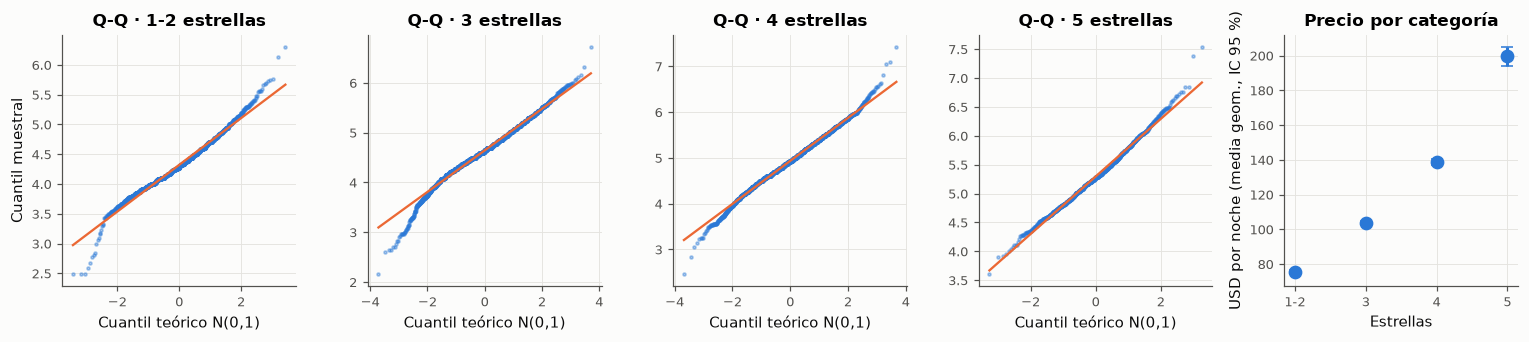

In [19]:
fig, ax = plt.subplots(1, 5, figsize=(14, 3.2))
for a, (g, d) in zip(
    ax[:4], anova_df.groupby("categoria", observed=True)["log_precio_noche"], strict=True
):
    stats.probplot(d, dist="norm", plot=a)
    a.get_lines()[0].set(markerfacecolor=gr.AZUL, markeredgecolor=gr.AZUL, markersize=2, alpha=0.4)
    a.get_lines()[1].set(color=gr.NARANJA, lw=1.5)
    a.set(
        title=f"Q-Q · {g} estrellas",
        xlabel="Cuantil teórico N(0,1)",
        ylabel="Cuantil muestral" if g == "1-2" else "",
    )
medias = anova_df.groupby("categoria", observed=True)["log_precio_noche"].agg(["mean", "sem"])
ax[4].errorbar(
    range(len(medias)),
    np.exp(medias["mean"]),
    yerr=[
        np.exp(medias["mean"]) - np.exp(medias["mean"] - 1.96 * medias["sem"]),
        np.exp(medias["mean"] + 1.96 * medias["sem"]) - np.exp(medias["mean"]),
    ],
    fmt="o",
    color=gr.AZUL,
    capsize=4,
    ms=8,
)
ax[4].set(
    xticks=range(len(medias)),
    xticklabels=medias.index,
    xlabel="Estrellas",
    ylabel="USD por noche (media geom., IC 95 %)",
    title="Precio por categoría",
)
fig.tight_layout()
gr.guardar(fig, "f1_anova")
plt.show()

**Supuestos.**
* *Normalidad:* Shapiro-Wilk rechaza en los cuatro grupos (p entre 2,4·10⁻²² y 3,4·10⁻⁵ con n ≤ 5.000),
  como anticipa el enunciado para muestras grandes. Lo relevante: asimetrías entre −0,213 y 0,314
  (dentro de $[-1, 1]$) y curtosis en exceso entre 0,49 y 1,61. Los Q-Q muestran colas algo más
  pesadas que la normal, sobre todo la izquierda en 1-2 y 3 estrellas. Con n ≥ 1.252 por grupo, el
  TCL garantiza la validez aproximada de las medias.
* *Homocedasticidad:* **Levene rechaza** (F(3; 16060) = 56,57, p = 2,27·10⁻³⁶; razón de varianzas
  máx/mín = 1,59). El F clásico pierde validez, así que la inferencia principal es el **ANOVA de
  Welch**.

**Decisión.** Se rechaza $H_0$ con las tres pruebas: Welch F(3; 4432,0) = 1807; F clásico(3; 16060)
= 1820; Kruskal-Wallis H(3) = 4150; en las tres, p < 10⁻³⁰⁰ (subdesborde de doble precisión). El
tamaño de efecto es grande: η² = 0,254, ω² = 0,254 y ε² = 0,258. La categoría explica ≈ 25 % de
la varianza del log precio.

**Post-hoc.** Las seis comparaciones son significativas con los tres criterios (Games-Howell,
Tukey HSD y Bonferroni), así que la conclusión no depende del supuesto de homocedasticidad. En
cocientes de medias geométricas, un hotel de 5 estrellas cuesta 2,65 veces uno de 1-2
(1/0,3773), 1,92 veces uno de 3 y 1,44 veces uno de 4. Los p-valores de Games-Howell que aparecen
como ≈ 10⁻¹³ o 0 son el límite numérico de la distribución de rango estudentizado en pingouin, no
valores exactos.

**Por qué Welch y no Kruskal-Wallis como principal:** la pregunta es sobre el **valor esperado**
del log precio (medias), y Welch responde exactamente eso sin suponer varianzas iguales.
Kruskal-Wallis contrasta otra hipótesis (dominancia estocástica) y queda como resguardo.

## 1.9 Síntesis de la Fase 1

| Hallazgo | Evidencia | Consecuencia para las fases siguientes |
|---|---|---|
| Hay sesgo de posición puro sobre el clic | Contraste 1: CTR ×2,16 en el top-5 con orden aleatorio | El arco $T \to M$ existe; el efecto sobre la reserva se estima en la Fase 4 |
| El algoritmo selecciona hoteles que se clickean igual | Curvas de CTR R = 0 vs. R = 1 | Confusión a corregir (Backdoor) |
| La categoría explica ≈ 25 % del log precio | ANOVA de Welch, η² = 0,254 | Multicolinealidad calidad–precio (VIF, Fase 2) |
| El gasto por reserva no difiere entre recurrentes y nuevos (no detectable bajo g ≈ 0,09) | Contraste 2 | $Z_u$ entra como confusor de la conversión, no del gasto |
| $Z_c$ = {`comp_n_info`, `comp_saldo`} son confusores | Tabla 1.4 | Entran al ajuste en la Fase 4 |
| Slots estructurales 5/11/17/23 fuera del dataset | Presencia por posición | T = top-5 en pantalla ≈ 4 hoteles del dataset |
| Faltantes MAR y MNAR estructurales, ninguno MCAR | Tabla 1.3 | Imputación por grupo + indicadores; los MNAR no se imputan |

---
# Fase 2 — Diagnóstico de Gauss-Markov, puntos influyentes y reducción PCA

## 2.0 Partición Train/Test (única para las Fases 2 a 4)

80/20 **agrupada por búsqueda** (ninguna lista queda partida entre Train y Test) y
**estratificada por `random_bool`**, con `SEED = 42` (`tpi.particion`). Toda la Fase 2 se estima
**solo con Train**; Test queda intacto para el torneo de la Fase 3. La partición es aleatoria y no
cronológica porque el período es corto (8 meses) y el objetivo es generalizar a búsquedas nuevas
del mismo período (ver Durbin-Watson en 2.2).

In [20]:
import statsmodels.api as sm
from sklearn.linear_model import HuberRegressor, RANSACRegressor

from tpi.particion import es_train
from tpi.regresion import ajustar_pca, diagnostico_gauss_markov, influencia, resumen_pca, tabla_vif

df["train"] = es_train(df)
print(
    df.groupby("train").agg(
        busquedas=("srch_id", "nunique"), filas=("srch_id", "size"), pct_R1=("random_bool", "mean")
    )
)

       busquedas   filas  pct_R1
train                           
False       6000  148509  0.4938
True       24000  590814  0.4905


## 2.1 Modelo lineal de referencia (MCO): precio hedónico del hotel reservado

**Unidad:** la reserva (una por búsqueda, así que las observaciones son independientes), en Train
y sin precios outlier. **Respuesta:** $Y = \log(\text{precio por noche})$. Las pendientes se leen
como semielasticidades: $100\,(e^{\beta_j}-1)$ % de cambio en el precio por unidad de $X_j$.

$$\log(\text{precio})_i = \beta_0 + \sum_{j=1}^{p} \beta_j X_{ij} + \varepsilon_i, \qquad
  \mathbb{E}[\varepsilon \mid X] = 0,\; \operatorname{Var}(\varepsilon \mid X) = \sigma^2 I$$

Bajo Gauss-Markov (linealidad, exogeneidad, homocedasticidad, no autocorrelación, rango completo)
el estimador MCO $\hat\beta = (X^\top X)^{-1}X^\top y$ es el de mínima varianza entre los lineales
insesgados. La normalidad de $\varepsilon$ solo hace falta para que las pruebas t y F sean exactas
en muestras chicas; con $n$ en miles valen asintóticamente.

**Contrastes:** $F$ global, $H_0: \beta_1 = \dots = \beta_p = 0$; $t$ individual,
$H_0: \beta_j = 0$.

**Experimento previo (fallido, Entrada 3).** Primero ajustamos la especificación ingenua: precio
crudo en USD, sin log y sin quitar outliers.

In [21]:
X_MCO = [
    "prop_starrating", "prop_review_score", "sin_resenas", "prop_location_score1",
    "prop_location_score2", "prop_log_historical_price", "sin_historial_precio", "prop_brand_bool",
    "promotion_flag", "srch_length_of_stay", "srch_booking_window", "srch_adults_count",
    "srch_children_count", "srch_room_count", "srch_saturday_night_bool", "usuario_recurrente",
    "random_bool",
]  # fmt: skip
reservas_tr = df[df.train & (df.booking_bool == 1)].sort_values("date_time").copy()
ingenuo = smf.ols("price_usd ~ " + " + ".join(X_MCO), reservas_tr).fit()
dg_ing = diagnostico_gauss_markov(ingenuo)
inf_ing = influencia(ingenuo)
print(
    f"INGENUO (precio crudo, con outliers): n = {int(ingenuo.nobs)}, R² = {ingenuo.rsquared:.4f}, "
    f"JB = {dg_ing.jb:.4g}, curtosis = {dg_ing.curtosis:.1f}, Cook máx = {inf_ing.cook.max():.3f}, "
    f"obs. con D > 0,5: {int(inf_ing.influyente_05.sum())}"
)

rtr = reservas_tr[reservas_tr.precio_outlier == 0].copy()
rtr["log_precio_noche"] = np.log(rtr["price_usd"])
FORMULA = "log_precio_noche ~ " + " + ".join(X_MCO)
mco = smf.ols(FORMULA, rtr).fit()
print(mco.summary().tables[0])
from tpi.inferencia import _p as formato_p

print(
    f"F global: F({int(mco.df_model)}; {int(mco.df_resid)}) = {mco.fvalue:.2f}, {formato_p(mco.f_pvalue)}"
)
ic_mco = mco.conf_int()
pd.DataFrame(
    {
        "coef": mco.params,
        "ee": mco.bse,
        "t": mco.tvalues,
        "p": mco.pvalues,
        "IC95_inf": ic_mco[0],
        "IC95_sup": ic_mco[1],
        "efecto_%": 100 * (np.exp(mco.params) - 1),
    }
).round(4)

C:\Users\veron\.venvs\tpi-eaymr\Lib\site-packages\statsmodels\stats\diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


INGENUO (precio crudo, con outliers): n = 12877, R² = 0.0028, JB = 7.975e+10, curtosis = 12192.8, Cook máx = 1.215, obs. con D > 0,5: 1
                            OLS Regression Results                            
Dep. Variable:       log_precio_noche   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                     1151.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:43:46   Log-Likelihood:                -3663.2
No. Observations:               12858   AIC:                             7362.
Df Residuals:                   12840   BIC:                             7497.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
F global: F(17; 12840) = 1150.64, p < 1e-300 (subdesborde de doble precisi

,coef,ee,t,p,IC95_inf,IC95_sup,efecto_%
Intercept,0.4368,0.0374,11.6695,0.0000,0.3634,0.5102,54.7744
prop_starrating,0.0601,0.0045,13.3645,0.0000,0.0513,0.0689,6.1950
prop_review_score,0.0546,0.0060,9.0621,0.0000,0.0428,0.0664,5.6070
sin_resenas,-0.0348,0.0190,-1.8378,0.0661,-0.0720,0.0023,-3.4238
prop_location_score1,0.0038,0.0022,1.7368,0.0824,-0.0005,0.0081,0.3805
prop_location_score2,0.0410,0.0158,2.6001,0.0093,0.0101,0.0720,4.1885
prop_log_historical_price,0.7664,0.0084,91.4622,0.0000,0.7500,0.7828,115.1991
sin_historial_precio,0.0463,0.0080,5.7802,0.0000,0.0306,0.0620,4.7410
prop_brand_bool,-0.0024,0.0063,-0.3793,0.7045,-0.0147,0.0099,-0.2382
promotion_flag,-0.1611,0.0065,-24.9053,0.0000,-0.1737,-0.1484,-14.8768


**Experimento fallido (Entrada 3).** El modelo ingenuo sobre el precio crudo explica el 0,28 % de la
varianza (R² = 0,0028, n = 12.877). Sus residuos tienen curtosis 12.192,8 (JB = 7,975·10¹⁰) y una
sola observación tiene distancia de Cook 1,215 (> 0,5): un precio imposible domina la estimación.
Las dos correcciones de la Fase 1 (log y outliers) lo resuelven.

**Modelo corregido** (n = 12.858 reservas de Train): R² = 0,604, R² ajustado = 0,603. El F global
rechaza $H_0$ de que todas las pendientes son nulas: F(17; 12840) = 1151 (p-valor exacto en la
salida). Lectura de los coeficientes significativos, como cambio porcentual del precio por noche:

* **Precio histórico del hotel** ($\beta$ = 0,766, t = 91,46): es casi una elasticidad. Un 1 % más
  de precio histórico se asocia con un 0,77 % más de precio actual; es el regresor dominante.
* **Estrellas** (+6,2 % por estrella, t = 13,36) y **reseñas** (+5,6 % por punto, t = 9,06),
  netos del precio histórico.
* **Promoción:** −14,9 % (t = −24,91), el descuento visible.
* **Usuario recurrente:** +4,7 % (t = 3,94). Los recurrentes reservan hoteles algo más caros por
  noche (compatible con el contraste 2 de la Fase 1, que no encontró diferencias en el gasto
  total).
* **No se rechaza $H_0$** para `random_bool` (p = 0,661): el precio del hotel reservado no
  difiere entre orden aleatorio y orden del algoritmo, condicional a sus atributos. Tampoco para
  marca (p = 0,705), ausencia de reseñas (p = 0,066) ni `location_score1` (p = 0,082).

Es un modelo **descriptivo** del precio, no causal: sirve de referencia para auditar los supuestos
de Gauss-Markov sobre datos reales.

## 2.2 Auditoría de los supuestos de Gauss-Markov

* **Homocedasticidad:** Breusch-Pagan ($H_0$: $\operatorname{Var}(\varepsilon\mid X) = \sigma^2$;
  LM $= nR^2$ de la regresión auxiliar de $\hat\varepsilon^2$ sobre $X$, $\chi^2_p$) y White
  (agrega cuadrados y productos cruzados).
* **Normalidad:** Jarque-Bera, $JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \sim \chi^2_2$, y Q-Q.
* **Independencia:** las reservas están ordenadas por fecha, así que el Durbin-Watson
  $d = \sum (\hat\varepsilon_t - \hat\varepsilon_{t-1})^2 / \sum \hat\varepsilon_t^2 \approx 2(1-\hat\rho)$
  mide autocorrelación temporal de primer orden.

In [22]:
dg = diagnostico_gauss_markov(mco)
print(f"Breusch-Pagan: LM = {dg.bp_lm:.2f}, gl = {dg.bp_gl}, {formato_p(dg.bp_p)}")
print(f"White: LM = {dg.white_lm:.2f}, {formato_p(dg.white_p)}")
print(
    f"Jarque-Bera: JB = {dg.jb:.2f}, {formato_p(dg.jb_p)} | asimetría = {dg.asimetria:.3f}, "
    f"curtosis = {dg.curtosis:.3f}"
)
print(f"Durbin-Watson (orden temporal): d = {dg.durbin_watson:.4f}")
mco_hc3 = smf.ols(FORMULA, rtr).fit(cov_type="HC3")
comp_ee = pd.DataFrame(
    {"coef": mco.params, "ee_MCO": mco.bse, "ee_HC3": mco_hc3.bse, "p_HC3": mco_hc3.pvalues}
)
comp_ee["razon_ee"] = comp_ee["ee_HC3"] / comp_ee["ee_MCO"]
comp_ee.round(4)

Breusch-Pagan: LM = 516.99, gl = 17, p = 4.96e-99
White: LM = 989.87, p = 1.71e-118
Jarque-Bera: JB = 4209.26, p < 1e-300 (subdesborde de doble precisión) | asimetría = 0.082, curtosis = 5.798
Durbin-Watson (orden temporal): d = 1.9515


C:\Users\veron\.venvs\tpi-eaymr\Lib\site-packages\statsmodels\stats\diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,coef,ee_MCO,ee_HC3,p_HC3,razon_ee
Intercept,0.4368,0.0374,0.0389,0.0000,1.0389
prop_starrating,0.0601,0.0045,0.0047,0.0000,1.0467
prop_review_score,0.0546,0.0060,0.0061,0.0000,1.0132
sin_resenas,-0.0348,0.0190,0.0230,0.1290,1.2107
prop_location_score1,0.0038,0.0022,0.0024,0.1118,1.0923
prop_location_score2,0.0410,0.0158,0.0166,0.0134,1.0513
prop_log_historical_price,0.7664,0.0084,0.0093,0.0000,1.1133
sin_historial_precio,0.0463,0.0080,0.0105,0.0000,1.3101
prop_brand_bool,-0.0024,0.0063,0.0066,0.7174,1.0481
promotion_flag,-0.1611,0.0065,0.0068,0.0000,1.0453


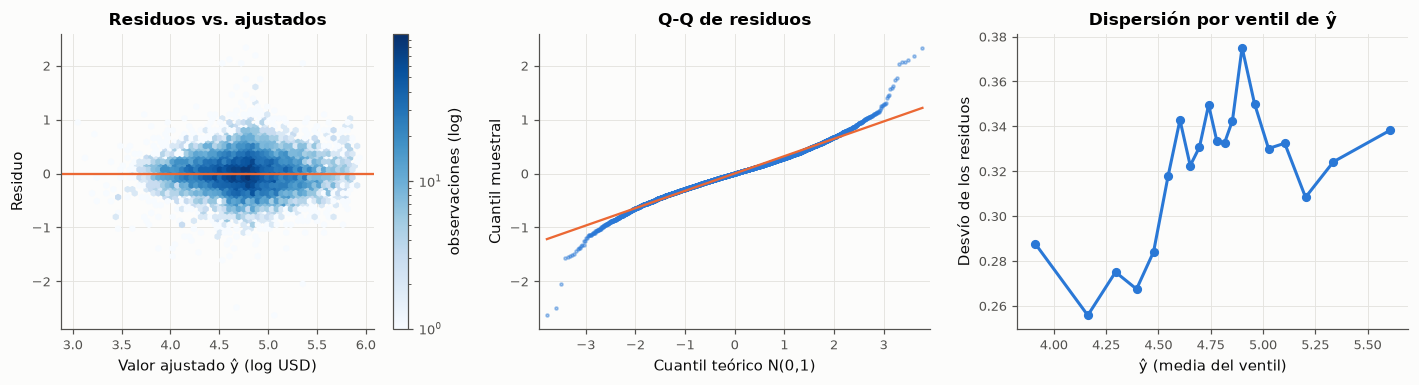

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
hb = ax[0].hexbin(
    mco.fittedvalues, mco.resid, gridsize=60, cmap=gr.SECUENCIAL, mincnt=1, bins="log"
)
ax[0].axhline(0, color=gr.NARANJA, lw=1.5)
ax[0].set(xlabel="Valor ajustado ŷ (log USD)", ylabel="Residuo", title="Residuos vs. ajustados")
fig.colorbar(hb, ax=ax[0], label="observaciones (log)")
sm.qqplot(
    mco.resid,
    line="s",
    ax=ax[1],
    markersize=2,
    alpha=0.4,
    markerfacecolor=gr.AZUL,
    markeredgecolor=gr.AZUL,
)
ax[1].get_lines()[1].set(color=gr.NARANJA, lw=1.5)
ax[1].set(title="Q-Q de residuos", xlabel="Cuantil teórico N(0,1)", ylabel="Cuantil muestral")
cuantiles = pd.qcut(mco.fittedvalues, 20)
disp = mco.resid.groupby(cuantiles, observed=True).std()
ax[2].plot(
    mco.fittedvalues.groupby(cuantiles, observed=True).mean(), disp, "o-", color=gr.AZUL, ms=5
)
ax[2].set(
    xlabel="ŷ (media del ventil)",
    ylabel="Desvío de los residuos",
    title="Dispersión por ventil de ŷ",
)
fig.tight_layout()
gr.guardar(fig, "f2_residuos")
plt.show()

**Homocedasticidad: se rechaza.** Breusch-Pagan LM = 516,99 (gl = 17, p = 4,96·10⁻⁹⁹) y White
LM = 989,87 (p = 1,71·10⁻¹¹⁸). El panel derecho lo muestra: el desvío de los residuos va de 0,26 a
0,37 según el nivel de precio ajustado. (El aviso de "matriz de rango incompleto" del test de White
viene de elevar al cuadrado regresores binarios, que son iguales a sí mismos: statsmodels lo
resuelve con pseudoinversa y no afecta el estadístico.)
**Remediación:** errores estándar robustos **HC3**. Los EE suben hasta un 31 %
(`sin_historial_precio`) y un 21 % (`sin_resenas`, cuyo p pasa de 0,066 a 0,129). Las
conclusiones sustantivas no cambian; los coeficientes MCO siguen siendo insesgados, solo era
incorrecta su varianza.

**Normalidad: se rechaza** (JB = 4209,26; p < 10⁻³⁰⁰), pero con asimetría 0,082 y **curtosis
5,798**: colas pesadas y simétricas, visibles en los extremos del Q-Q. Con n = 12.858, los
contrastes t y F siguen siendo válidos asintóticamente (TCL); las colas pesadas motivan los
estimadores robustos de 2.3.

**Independencia:** Durbin-Watson = 1,9515 con las reservas en orden temporal, compatible con
ausencia de autocorrelación de primer orden ($\hat\rho \approx 1 - d/2 = 0{,}024$). Respalda la
partición aleatoria (no cronológica) de 2.0.

## 2.3 Observaciones extremas y puntos influyentes

* Residuo estudentizado externo: $r_i = \hat\varepsilon_i / (\hat\sigma_{(i)}\sqrt{1-h_{ii}})$; outlier de respuesta si $|r_i| > 3$.
* Leverage $h_{ii}$ (diagonal de $H = X(X^\top X)^{-1}X^\top$): extremo en $X$ si $h_{ii} > 2(p+1)/n$.
* Cook: $D_i = \frac{\hat\varepsilon_i^2}{(p+1)\,\mathrm{MSE}}\left[\frac{h_{ii}}{(1-h_{ii})^2}\right]$; influyente si $D_i > 4/n$ o $D_i > 0{,}5$.

**¿Error de medición o caso real?** Cruzamos los influyentes con el diagnóstico de escala del precio
de la Fase 1 (reservas cuyo gasto es compatible con precio por noche, por estadía o con ninguno).

In [24]:
inf = influencia(mco)
n_obs, k = int(mco.nobs), mco.model.exog.shape[1]
print(f"n = {n_obs}, p + 1 = {k} | umbrales: h > {2 * k / n_obs:.5f}, D > {4 / n_obs:.6f}")
print(
    inf[["outlier_y", "alto_leverage", "influyente_4n", "influyente_05"]].sum().to_dict(),
    f"| D máx = {inf.cook.max():.4f}",
)
esc_tr = diagnostico_escala_precio(rtr)[["escala"]]
cruce = (
    rtr[[]]
    .join(esc_tr)
    .fillna({"escala": "1 noche (sin ambigüedad)"})
    .join(inf[["influyente_4n", "outlier_y"]])
)
cruce.groupby("escala")[["influyente_4n", "outlier_y"]].agg(["mean", "size"]).round(4)

n = 12858, p + 1 = 18 | umbrales: h > 0.00280, D > 0.000311
{'outlier_y': 119, 'alto_leverage': 843, 'influyente_4n': 746, 'influyente_05': 0} | D máx = 0.0117


influyente_4n       outlier_y      
                                  mean  size      mean  size
escala                                                      
1 noche (sin ambigüedad)        0.0485  6268    0.0083  6268
incompatible                    0.0951   610    0.0262   610
por_estadia                     0.0791   215    0.0186   215
por_noche                       0.0637  5765    0.0082  5765

In [25]:
y_r, X_r = rtr["log_precio_noche"], rtr[X_MCO].astype(float)
huber = HuberRegressor(epsilon=1.35, max_iter=1000).fit(X_r, y_r)
# RANSAC con el umbral por defecto (MAD de y, no de los residuos): experimento fallido (Entrada 3)
ransac = RANSACRegressor(random_state=SEED).fit(X_r, y_r)
# RANSAC corregido: umbral = 3 · σ robusto de los residuos MCO (1,4826 · MAD)
sigma_rob = 1.4826 * np.median(np.abs(mco.resid - np.median(mco.resid)))
ransac3 = RANSACRegressor(residual_threshold=3 * sigma_rob, random_state=SEED).fit(X_r, y_r)
sin_inf = smf.ols(FORMULA, rtr[~inf["influyente_4n"].to_numpy()]).fit()
robustez = pd.DataFrame(
    {
        "MCO": mco.params[X_MCO],
        "MCO sin D>4/n": sin_inf.params[X_MCO],
        "Huber": pd.Series(huber.coef_, index=X_MCO),
        "RANSAC (defecto)": pd.Series(ransac.estimator_.coef_, index=X_MCO),
        "RANSAC (3σ rob.)": pd.Series(ransac3.estimator_.coef_, index=X_MCO),
    }
)
print(
    f"RANSAC defecto: {ransac.inlier_mask_.mean():.2%} de inliers | RANSAC 3σ: "
    f"{ransac3.inlier_mask_.mean():.2%} | Huber: {np.mean(huber.outliers_):.2%} marcados como outliers"
)
print(
    "Máx. |coef − MCO sin influyentes|:",
    (robustez.drop(columns="MCO sin D>4/n").sub(robustez["MCO sin D>4/n"], axis=0))
    .abs()
    .max()
    .round(4)
    .to_dict(),
)
print(f"R² MCO sin influyentes: {sin_inf.rsquared:.4f} (n = {int(sin_inf.nobs)})")
robustez.round(4)

RANSAC defecto: 55.02% de inliers | RANSAC 3σ: 89.03% | Huber: 37.16% marcados como outliers
Máx. |coef − MCO sin influyentes|: {'MCO': 0.0232, 'Huber': 0.0121, 'RANSAC (defecto)': 0.3413, 'RANSAC (3σ rob.)': 0.0579}
R² MCO sin influyentes: 0.6857 (n = 12112)


,MCO,MCO sin D>4/n,Huber,RANSAC (defecto),RANSAC (3σ rob.)
prop_starrating,0.0601,0.0453,0.0463,-0.0457,0.0586
prop_review_score,0.0546,0.0454,0.0454,-0.0619,0.0742
sin_resenas,-0.0348,-0.0136,-0.0015,0.0014,0.0086
prop_location_score1,0.0038,-0.0004,0.0001,-0.0067,0.0219
prop_location_score2,0.0410,0.0556,0.0558,0.0994,0.0687
prop_log_historical_price,0.7664,0.7791,0.7837,0.9923,0.8224
sin_historial_precio,0.0463,0.0232,0.0269,-0.2536,0.0253
prop_brand_bool,-0.0024,-0.0105,-0.0088,-0.0067,-0.0027
promotion_flag,-0.1611,-0.1570,-0.1502,0.0579,-0.1875
srch_length_of_stay,0.0062,0.0059,0.0052,0.0620,-0.0121


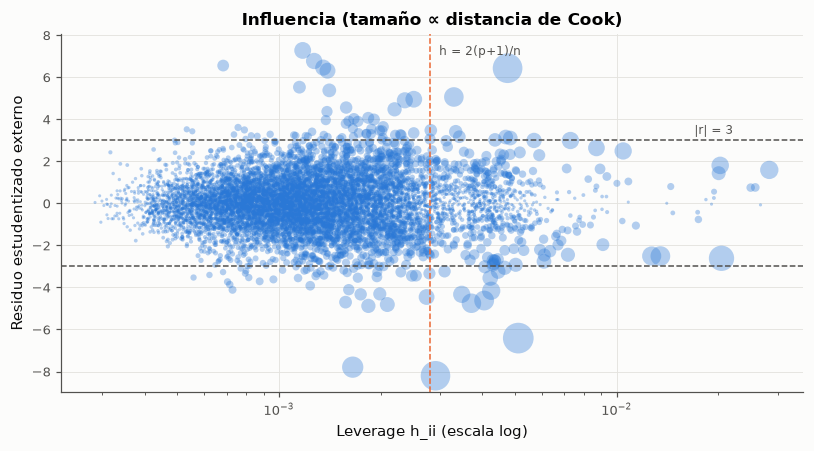

In [26]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
tam = 4 + 400 * inf["cook"] / inf["cook"].max()
ax.scatter(inf["leverage"], inf["r_ext"], s=tam, color=gr.AZUL, alpha=0.35, lw=0)
ax.axhline(3, color=gr.TEXTO_2, ls="--", lw=1)
ax.axhline(-3, color=gr.TEXTO_2, ls="--", lw=1)
ax.axvline(2 * k / n_obs, color=gr.NARANJA, ls="--", lw=1)
ax.annotate("|r| = 3", xy=(inf.leverage.max() * 0.6, 3.3), fontsize=8, color=gr.TEXTO_2)
ax.annotate(
    "h = 2(p+1)/n",
    xy=(2 * k / n_obs, inf.r_ext.max() * 0.97),
    xytext=(6, 0),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
ax.set(
    xscale="log",
    xlabel="Leverage h_ii (escala log)",
    ylabel="Residuo estudentizado externo",
    title="Influencia (tamaño ∝ distancia de Cook)",
)
fig.tight_layout()
gr.guardar(fig, "f2_influencia")
plt.show()

**Diagnóstico** (n = 12.858, p + 1 = 18): 119 outliers de respuesta (|r| > 3), 843 puntos de alto
leverage (h > 0,0028) y 746 influyentes según D > 4/n = 0,000311. **Ningún punto supera
D = 0,5** (D máx = 0,0117). No hay un punto que, por sí solo, mueva la recta; hay un grupo de
puntos moderadamente influyentes.

**¿Error de medición o caso real?** Cruzado con el diagnóstico de escala del precio (Fase 1), la
tasa de influyentes es del 4,85 % en reservas de 1 noche y del 6,37 % en las compatibles con
precio por noche, pero sube al **7,91 %** en las de precio por estadía y al **9,51 %** en las
incompatibles con ambas escalas. Lo mismo ocurre con los outliers de respuesta: 0,82-0,83 %
contra 1,86 % y 2,62 %. **Parte de la influencia es error de medición** (precio informado en la
escala equivocada). El resto son casos reales de colas pesadas.

**Regresión robusta:**
* Quitar los 746 influyentes sube el R² a 0,6857 y cambia los coeficientes a lo sumo en 0,023
  (estrellas: 0,060 → 0,045).
* **Huber** ($\epsilon$ = 1,35) llega casi a los mismos coeficientes que MCO sin influyentes
  (diferencia máxima 0,012) sin descartar datos: es la especificación de resguardo.
* **RANSAC con el umbral por defecto: experimento fallido (Entrada 3).** El umbral por defecto es
  la MAD de *y*, no de los residuos, y con 17 regresores deja solo el 55,02 % de inliers. Los
  coeficientes se vuelven inestables: estrellas −0,046, habitaciones +0,312; diferencia máxima con
  MCO sin influyentes, 0,341.
* Con el umbral corregido (3 σ̂ robustos de los residuos MCO) retiene el 89,03 % y la diferencia
  máxima baja a 0,058.

**Decisión:** MCO con errores HC3 como especificación principal, y Huber como resguardo. Los
influyentes no se eliminan: la mayoría son casos reales, y la parte que es error de medición ya
está neutralizada en las fases siguientes por el precio relativo a la búsqueda.

## 2.4 Multicolinealidad (VIF)

$\mathrm{VIF}_j = 1/(1-R_j^2)$, donde $R_j^2$ es el de la regresión de $X_j$ sobre los demás
regresores. Mide cuánto se infla $\operatorname{Var}(\hat\beta_j)$ respecto de regresores
ortogonales. Umbrales: 5 (atención) y 10 (severa). Lo calculamos para el modelo de 2.1 y para el
conjunto ampliado que usará el torneo de la Fase 3 (agrega precio, precio relativo, competidores y
posición).

In [27]:
X_AMPLIADO = X_MCO + [
    "log_precio",
    "log_precio_rel",
    "comp_n_info",
    "position",
    "prop_location_score2_faltante",
]
vif = pd.concat(
    {
        "VIF modelo 2.1": tabla_vif(rtr[X_MCO]),
        "VIF conjunto ampliado (Fase 3)": tabla_vif(df.loc[df.train, X_AMPLIADO]),
    },
    axis=1,
)
vif.sort_values("VIF conjunto ampliado (Fase 3)", ascending=False).round(2).head(10)

,VIF modelo 2.1,VIF conjunto ampliado (Fase 3)
log_precio,NaN,2.98
prop_log_historical_price,1.74,2.63
prop_starrating,1.70,1.97
log_precio_rel,NaN,1.92
prop_location_score1,1.28,1.54
prop_review_score,1.30,1.43
srch_booking_window,1.08,1.42
comp_n_info,NaN,1.41
srch_adults_count,1.30,1.29
srch_room_count,1.30,1.29


**No hay multicolinealidad relevante.** En el modelo de 2.1 el VIF máximo es 1,74 (precio
histórico) y 1,70 (estrellas). En el conjunto ampliado de la Fase 3 el máximo es 2,98
(`log_precio`), seguido por 2,63 (precio histórico) y 1,97 (estrellas). Ninguna variable se acerca a
5. **Corrige una anticipación de la Fase 1:** las correlaciones de a pares de hasta 0,62 entre
estrellas y precio histórico hacían esperar multicolinealidad, pero un $R^2_j$ auxiliar de a lo sumo
1 − 1/2,98 = 0,66 no infla las varianzas en forma preocupante (se registra en la Entrada 3).
**Decisión:** no se eliminan ni combinan regresores por colinealidad. La regularización Ridge/Lasso
de la Fase 3 se justifica por selección y estabilidad predictiva, no por un VIF alto.

## 2.5 Reducción de dimensionalidad con PCA (sin fuga de datos)

**Regla estricta:** la estandarización (media y desvío) y la descomposición espectral de la matriz
de correlaciones se calculan **solo con las filas de Train**; Test se proyecta con esa misma
rotación (`pipe.transform`), sin reajustar. `tests/test_fase2.py::test_pca_se_ajusta_solo_con_train`
lo verifica.

Variables: atributos continuos del hotel en la fila búsqueda × hotel (la unidad del torneo de la
Fase 3). Criterios de retención: codo del scree plot y Kaiser ($\lambda_k > 1$ sobre variables
estandarizadas).

In [28]:
X_PCA = [
    "prop_starrating", "prop_review_score", "prop_location_score1", "prop_location_score2",
    "prop_log_historical_price", "log_precio", "log_precio_rel", "promotion_flag",
    "prop_brand_bool", "comp_n_info",
]  # fmt: skip
pca_pipe = ajustar_pca(df[df.train], X_PCA, seed=SEED)
var_pca, cargas = resumen_pca(pca_pipe, X_PCA)
n_kaiser = int((var_pca["autovalor"] > 1).sum())
print(
    f"Kaiser (λ > 1): {n_kaiser} componentes, {var_pca['pct_acum'].iloc[n_kaiser - 1]:.1f} % de la varianza"
)
Z_test = pca_pipe.transform(df.loc[~df.train, X_PCA].astype(float))
print(f"Test proyectado con la rotación de Train: {Z_test.shape}")
var_pca.round(3)

Kaiser (λ > 1): 4 componentes, 69.7 % de la varianza
Test proyectado con la rotación de Train: (148509, 10)


,autovalor,pct_var,pct_acum
PC1,3.264,32.643,32.643
PC2,1.515,15.154,47.797
PC3,1.184,11.840,59.637
PC4,1.002,10.017,69.654
PC5,0.749,7.492,77.146
PC6,0.637,6.368,83.515
PC7,0.572,5.723,89.238
PC8,0.455,4.547,93.785
PC9,0.405,4.045,97.830
PC10,0.217,2.170,100.000


In [29]:
cargas.iloc[:, :4].round(3)

,PC1,PC2,PC3,PC4
prop_starrating,0.441,-0.003,-0.018,0.209
prop_review_score,0.351,-0.226,0.017,0.093
prop_location_score1,0.248,0.547,0.102,-0.208
prop_location_score2,0.153,0.480,0.088,-0.543
prop_log_historical_price,0.468,0.026,-0.011,0.054
log_precio,0.470,-0.105,-0.100,-0.077
log_precio_rel,0.387,-0.303,-0.120,-0.075
promotion_flag,0.063,0.379,0.171,0.745
prop_brand_bool,0.001,-0.413,0.576,-0.193
comp_n_info,0.065,0.041,0.771,0.050


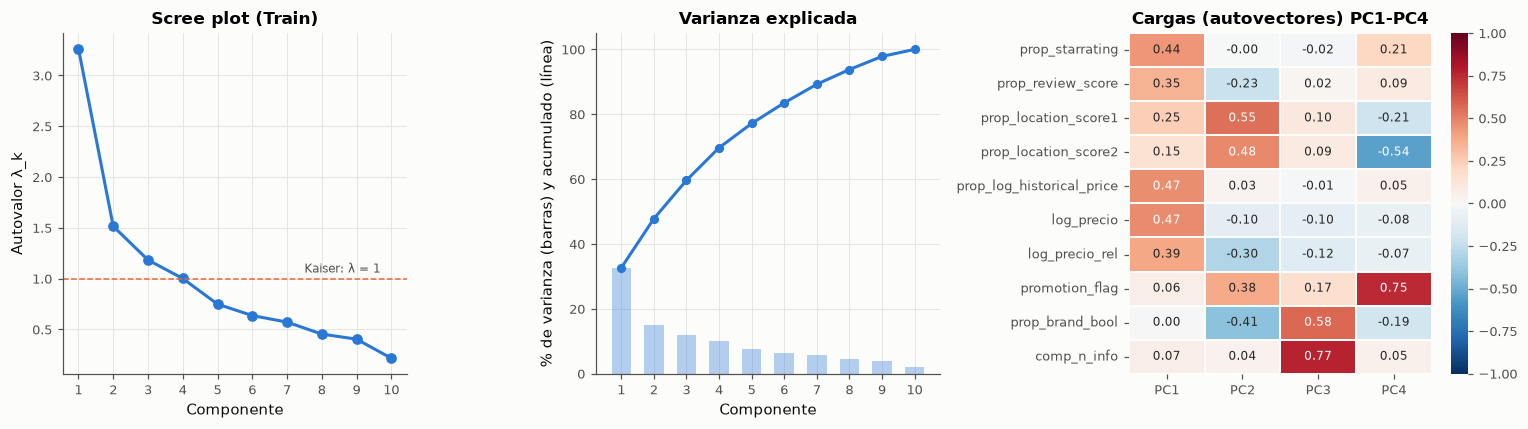

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1, 1.1]})
pcs = np.arange(1, len(var_pca) + 1)
ax[0].plot(pcs, var_pca["autovalor"], "o-", color=gr.AZUL, ms=6)
ax[0].axhline(1, color=gr.NARANJA, ls="--", lw=1)
ax[0].annotate("Kaiser: λ = 1", xy=(len(pcs) - 2.5, 1.06), fontsize=8, color=gr.TEXTO_2)
ax[0].set(xlabel="Componente", ylabel="Autovalor λ_k", title="Scree plot (Train)", xticks=pcs)
ax[1].bar(pcs, var_pca["pct_var"], color=gr.AZUL, alpha=0.35, width=0.6)
ax[1].plot(pcs, var_pca["pct_acum"], "o-", color=gr.AZUL, ms=5)
ax[1].set(
    xlabel="Componente",
    ylabel="% de varianza (barras) y acumulado (línea)",
    title="Varianza explicada",
    xticks=pcs,
    ylim=(0, 105),
)
sns.heatmap(
    cargas.iloc[:, :4],
    cmap=gr.DIVERGENTE,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=1,
    linecolor=gr.SUPERFICIE,
    ax=ax[2],
)
ax[2].set_title("Cargas (autovectores) PC1-PC4")
ax[2].grid(False)
fig.tight_layout()
gr.guardar(fig, "f2_pca")
plt.show()

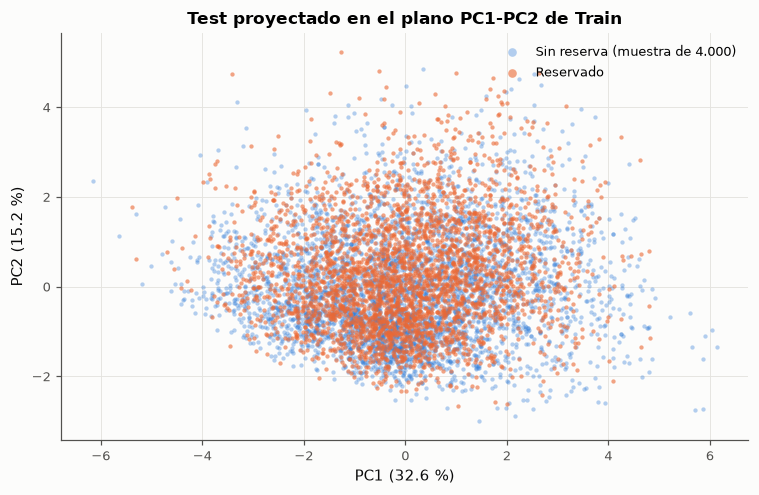

,PC1,PC2
reserva,,
0,-0.0063,-0.0035
1,0.0070,0.2704


In [31]:
proy = pd.DataFrame(Z_test[:, :2], columns=["PC1", "PC2"]).assign(
    reserva=df.loc[~df.train, "booking_bool"].to_numpy()
)
muestra_proy = pd.concat(
    [proy[proy.reserva == 0].sample(4000, random_state=SEED), proy[proy.reserva == 1]]
)
fig, ax = plt.subplots(figsize=(7, 4.6))
for r, color, nombre in [
    (0, gr.AZUL, "Sin reserva (muestra de 4.000)"),
    (1, gr.NARANJA, "Reservado"),
]:
    d = muestra_proy[muestra_proy.reserva == r]
    ax.scatter(d.PC1, d.PC2, s=8, color=color, alpha=0.35 if r == 0 else 0.6, lw=0, label=nombre)
ax.set(
    xlabel=f"PC1 ({var_pca.pct_var.iloc[0]:.1f} %)",
    ylabel=f"PC2 ({var_pca.pct_var.iloc[1]:.1f} %)",
    title="Test proyectado en el plano PC1-PC2 de Train",
)
ax.legend(loc="upper right", markerscale=2)
fig.tight_layout()
gr.guardar(fig, "f2_pca_plano")
plt.show()
proy.groupby("reserva")[["PC1", "PC2"]].mean()

**Retención.** Kaiser retiene **4 componentes** (λ = 3,264; 1,515; 1,184; 1,002), que explican el
69,7 % de la varianza. El cuarto está en el límite (λ = 1,002). El codo del scree plot está en la
2.ª componente (de 3,26 a 1,52, y después la caída se suaviza). **Decisión:** 2 componentes para la
visualización (plano PC1-PC2 de la app, módulo de diagnóstico) y 4 para el conjunto alternativo de
features que se pone a prueba en la Fase 3.

**Interpretación de negocio de las cargas:**
* **PC1 (32,6 %): "categoría y precio".** Cargas positivas y parecidas en estrellas (0,44), precio
  histórico (0,47), precio (0,47), precio relativo (0,39) y reseñas (0,35). Ordena los hoteles de
  económicos a premium.
* **PC2 (15,2 %): "buena ubicación a buen precio, independiente".** Ubicación (0,55 y 0,48) y
  promoción (0,38), con signo opuesto al de cadena (−0,41) y al precio relativo (−0,30).
* PC3 (11,8 %): cobertura de competidores (0,77) y pertenencia a cadena (0,58).
  PC4 (10,0 %): promoción (0,75) frente a `location_score2` (−0,54).

**Proyección ciega de Test.** Los hoteles reservados tienen PC2 medio = 0,270, contra −0,0035 de
los no reservados. En PC1 la diferencia es mínima (0,0070 vs. −0,0063). **Lo que se reserva no es
lo más caro ni lo de mayor categoría, sino lo bien ubicado, en promoción y barato para su
búsqueda.** Es un hallazgo predictivo, no causal (Fase 4).

## 2.6 Síntesis de la Fase 2

| Supuesto / análisis | Resultado | Remediación |
|---|---|---|
| Especificación | Precio crudo: R² = 0,0028, Cook máx 1,215 (fallido) | log(precio) sin outliers: R² = 0,604 |
| Homocedasticidad | Se rechaza (BP p = 4,96·10⁻⁹⁹; White p = 1,71·10⁻¹¹⁸) | Errores HC3 (EE hasta +31 %) |
| Normalidad | Se rechaza (JB), curtosis 5,80, asimetría 0,08 | TCL (n = 12.858) + estimador robusto de Huber |
| Independencia | DW = 1,95 | Ninguna; respalda la partición aleatoria |
| Influyentes | 746 con D > 4/n, ninguno con D > 0,5; más frecuentes con escala de precio errónea | Huber como resguardo; RANSAC con umbral 3σ̂ (el de defecto falla) |
| Multicolinealidad | VIF máx 1,74 (modelo) y 2,98 (conjunto Fase 3) | Ninguna |
| PCA (solo Train) | 4 comp. por Kaiser (69,7 %), codo en 2; PC1 = categoría-precio, PC2 = ubicación/promoción | 2 PCs para la app, 4 como features alternativas en la Fase 3 |